# Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glhmm import glhmm, preproc, utils, graphics
import mne
from pathlib import Path

from scipy import signal
from scipy.ndimage import uniform_filter1d

In [ ]:
N_STATES = 5 # Number of hidden states in the GLHMM
NAP_DURATION_MIN = 30 # Keep the first N minutes of each subject's EXPERIMENT_STAGE
EXPERIMENT_STAGE = 'Nap1'
COVTYPE = 'full' # 'full' or 'diag' or 'sharedfull'

FULL_STAGE = True # If False, only the first NAP_DURATION_MIN minutes of each subject's EXPERIMENT_STAGE are kept
PREPROC = True 
SLEEP_STAGES = True # Train on slow band-power envelopes  instead of the raw EEG signal
VERBOSE = False
SHOW_BAD_SPANS = True  # show the spans annotated as bad under the hidden states (sleep stage plot)
REMOVE_BAD_SPANS = False  # TODO: remove the spans annotated as bad in the preprocessing

GAMM_DIR = Path('C:/Users/eva/Documents/Master/ICM/Ilo/GAMM')
out_dir = Path('C:/Users/eva/Documents/Master/ICM/Ilo/GLHMM/outputs')

BANDS = {'delta': (0.5, 4), 'theta': (4, 8), 'alpha': (8, 12), 'sigma': (12, 16), 'beta': (16, 30)}
# Channels are pooled by region
REGIONS = {'Frontal': ['Fp', 'AF', 'F'], 'Central': ['FC', 'C', 'CP'], 'Temporal': ['FT', 'T', 'TP'],
           'Parietal': ['P'], 'Occipital': ['PO', 'O']}
ENV_SMOOTH_S = 2  # moving-average window applied to the envelopes (s)
FS_ENV = 4        # Hz: sampling rate of the envelopes given to the HMM


# Add physiological features
EMG_BAND = (20, 35)  # Hz: above ECG/movement leakage, steep cut below the 50 Hz line noise left at the 100 Hz Nyquist
# EOG features: name -> (band in Hz, smoothing in s)
EOG_FEATURES = {
    'EOG slow': ((0.1, 0.5), 10),  # slow eye movements (one sweep every 2-10 s, so 10 s smoothing), below the 0.3-40 Hz EEG band
    'EOG fast': ((0.5, 5), ENV_SMOOTH_S),  # blinks and saccades; in sleep it also picks up frontal delta and K-complexes
}


# Load and prepare data
Each `EEG/<subject>_preproc_raw.fif` is one continuous ~3h recording, already preprocessed by `preprocessing.ipynb` / `helpers/preprocessing.py` (50 Hz notch, band-pass, 100 Hz, bad channels interpolated, average reference, bad time spans annotated). No preprocessing is done here: the first `NAP_DURATION_MIN` minutes of Nap2 are cropped. The spans annotated as bad are kept, so a session here = the whole Nap2 window of one subject (`bad_s` in `sessions_meta` gives how much of it is annotated as bad).

In [22]:
data_dir = Path('C:/Users/eva/Documents/Master/ICM/Ilo/EEG')

fif_files = sorted(data_dir.glob('*_preprocessed.fif'))
if VERBOSE: print(f"Found {len(fif_files)} files: {[f.name for f in fif_files]}")
assert fif_files, f'no preprocessed file in {data_dir}: run preprocessing.ipynb (or helpers/preprocessing.py) first'

In [23]:
if VERBOSE:
    channel_counts = []
    for f in fif_files:
        raw_info = mne.io.read_raw_fif(f, preload=False, verbose=False)
        eeg_channels = mne.pick_types(raw_info.info, eeg=True)
        channel_counts.append({
            'subject': f.name.replace('_preproc_raw.fif', ''),
            'file': f.name,
            'total_channels': len(raw_info.ch_names),
            'eeg_channels': len(eeg_channels),
        })

    channel_counts = pd.DataFrame(channel_counts)
    print(channel_counts.to_string(index=False))

In [24]:
# Which raw 'Session N' is Nap2 differs between subjects (e.g. TT004 -> Session 7), so take the mapping from the GAMM tables
session_map = pd.read_csv(GAMM_DIR / '09_presses_staged.csv')[['subname', 'session', 'session_raw']].drop_duplicates()
data_raw = session_map[session_map.session == EXPERIMENT_STAGE].set_index('subname').session_raw 
stages_df = pd.read_csv(GAMM_DIR / '08_sleep_stages.csv')
# onset_s is in seconds from the start of the recording stored in dictionnary subject:start
start_s = {sub: stages_df[(stages_df.subname == sub) & (stages_df.session == sess) & stages_df.event.str.startswith('Start')].onset_s.min()
                for sub, sess in data_raw.items()}
end_s = {sub: stages_df[(stages_df.subname == sub) & (stages_df.session == sess) & stages_df.event.str.startswith('End')].onset_s.max()
              for sub, sess in data_raw.items()}
if VERBOSE: print(f"{EXPERIMENT_STAGE} start times (s from recording start): {start_s}")
if VERBOSE: print(f"{EXPERIMENT_STAGE} end times (s from recording start): {end_s}")

EPOCH_S = 30
# Hypnogram: one row per scored 30-s epoch (08_sleep_stages only has the epochs that contain an event)
hyp_df = pd.read_csv(GAMM_DIR / '12_hypnogram_epochs.csv')
hyp_df = hyp_df[hyp_df.recording_part != 'part2']  # part2 files are skipped below and restart epoch_idx at 0
sleep_stages = {sub: g.set_index('epoch_idx').sleep_stage.to_dict() for sub, g in hyp_df.groupby('subname')}
Y_list = []
starts, ends = [], []
meta_rows = []
offset = 0

for f in fif_files:
    subject = f.stem.split('_')[0]  # e.g. 'TT013_a_preproc_raw' -> 'TT013'
    if VERBOSE: print(f"Processing {subject} from file {f.name}...")
    if subject in ['TT003']:
         continue  # skip this subject because it has unusable EEG
    if f.name.__contains__('part2'):
        continue  # skip this file (all Nap2 windows lie in the main recording)
    if np.isnan(start_s.get(subject, np.nan)):
        print(f"  no {EXPERIMENT_STAGE} start found for {subject}, skipping")
        continue

    crop_start_s = start_s[subject]
    raw = mne.io.read_raw_fif(f, preload=False, verbose=0)
    if not FULL_STAGE: # only keep the first NAP_DURATION_MIN minutes of the EXPERIMENT_STAGE
        raw.crop(tmin=crop_start_s, tmax=crop_start_s + NAP_DURATION_MIN * 60, include_tmax=False)
    else: # keep the full EXPERIMENT_STAGE
        crop_end_s = end_s[subject]
        raw.crop(tmin=crop_start_s, tmax=crop_end_s, include_tmax=False)

    raw.pick('eeg')  # drop EMG/ECG/respiration/finger/IO
    fs = int(raw.info['sfreq'])
    ch_names = raw.ch_names
    # Spans annotated as bad in this window, in s from its start (crop keeps only the annotations inside it)
    bad_spans = [(max(o - raw.first_time, 0), min(o - raw.first_time + d, raw.times[-1]))
                 for o, d, desc in zip(raw.annotations.onset, raw.annotations.duration, raw.annotations.description)
                 if desc.upper().startswith('BAD')]
    bad_s = sum(b - a for a, b in bad_spans)

    # (n_times, n_channels), volts -> microvolts. The bad spans are kept, so each subject is one continuous session
    X = raw.get_data(reject_by_annotation=None, verbose=0).T.astype(np.float32) * 1e6
    del raw  # free before loading next subject's data

    Y_list.append(X)
    starts.append(offset)
    ends.append(offset + len(X))
    offset += len(X)
    meta_rows.append({
        'subject': subject,
        'file': str(f),
        'start': starts[-1],
        'end': ends[-1],
        'crop_start_s': crop_start_s,  # absolute time (s from recording start) of the first sample
        'duration_min': round(len(X) / fs / 60, 1),
        'bad_s': round(bad_s, 1),
        'bad_spans': bad_spans,
    })
    print(f"  {subject}: {len(X) / fs / 60:.1f} min, of which {bad_s:.0f} s ({bad_s / (len(X) / fs):.1%}) annotated as bad and kept")

assert len({x.shape[1] for x in Y_list}) == 1, 'sessions have different channel counts'
Y = np.vstack(Y_list)
del Y_list
indices = np.column_stack([starts, ends])
sessions_meta = pd.DataFrame(meta_rows)

print(f'\nY shape: {Y.shape}  (n_samples_total x n_channels)')
print(f'indices shape: {indices.shape}  (n_sessions x 2, {sessions_meta.subject.nunique()} subjects)')
print(f'{len(ch_names)} EEG channels, fs = {fs} Hz')
print(f'Y size in memory: {Y.nbytes / 1e9:.2f} GB')
sessions_meta

C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3584720478.py:35: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT001_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(f, preload=False, verbose=0)


  TT001: 31.4 min, of which 0 s (0.0%) annotated as bad and kept


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3584720478.py:35: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT002_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(f, preload=False, verbose=0)


  TT002: 18.1 min, of which 0 s (0.0%) annotated as bad and kept


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3584720478.py:35: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT004_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(f, preload=False, verbose=0)


  TT004: 23.6 min, of which 0 s (0.0%) annotated as bad and kept


... (21 outputs left out)

  TT017: 6.7 min, of which 0 s (0.0%) annotated as bad and kept


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\3584720478.py:35: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT018_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(f, preload=False, verbose=0)


  TT018: 32.5 min, of which 30 s (1.5%) annotated as bad and kept
  no Nap1 start found for TT019, skipping

Y shape: (2034421, 63)  (n_samples_total x n_channels)
indices shape: (15, 2)  (n_sessions x 2, 15 subjects)
63 EEG channels, fs = 100 Hz
Y size in memory: 0.51 GB


,subject,file,start,end,crop_start_s,duration_min,bad_s,bad_spans
0,TT001,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,0,188166,3033.152,31.4,0.0,[]
1,TT002,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,188166,296970,1864.574,18.1,0.0,[]
2,TT004,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,296970,438668,2633.054,23.6,0.0,[]
3,TT005,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,438668,618120,3528.884,29.9,2.1,"[(1231.9700979999998, 1234.0701956562498)]"
4,TT006,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,618120,701009,2091.290,13.8,5.1,"[(139.00003900000002, 144.14994134375002)]"
5,TT007,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,701009,791286,2312.452,15.0,0.0,[]
6,TT008,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,791286,989049,3117.180,33.0,6.2,"[(1831.670098, 1835.73992221875), (1865.380059..."
7,TT009,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT00...,989049,1114082,2661.852,20.8,6.3,"[(496.44003900000007, 499.19003900000007), (11..."
8,TT011,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT01...,1114082,1308570,2585.444,32.4,0.0,[]
9,TT012,C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT01...,1308570,1363719,2676.804,9.2,0.0,[]


In [25]:
def band_power_envelopes(X, fs):
    """(n_times, n_channels) EEG -> (n_times_env, n_regions * n_bands) log band envelopes."""
    prefix = [c.rstrip('0123456789z') for c in ch_names]
    region_idx = {r: [i for i, pr in enumerate(prefix) if pr in pre] for r, pre in REGIONS.items()}
    step = int(fs / FS_ENV)
    feats = []
    for lo, hi in BANDS.values():
        sos = signal.butter(4, (lo, hi), 'bandpass', output='sos', fs=fs)
        env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, X, axis=0), axis=0))
        for idx in region_idx.values():
            e = np.median(env[:, idx], axis=1)  # median over channels: robust to a single bad electrode
            e = uniform_filter1d(e, int(ENV_SMOOTH_S * fs), mode='nearest')[step // 2::step]
            feats.append(np.log(e))
    return np.column_stack(feats)


if SLEEP_STAGES:
    Y_prep = [band_power_envelopes(Y[a:b], fs) for a, b in indices]
    ends_prep = np.cumsum([x.shape[0] for x in Y_prep])
    indices_prep = np.column_stack([ends_prep - [x.shape[0] for x in Y_prep], ends_prep])
    Y_prep = np.vstack(Y_prep)
    # Standardise within each subject, over all its sessions: differences between two sessions of a subject are kept
    for sub in sessions_meta.subject.unique():
        rows = np.concatenate([np.arange(a, b) for a, b in indices_prep[(sessions_meta.subject == sub).values]])
        Y_prep[rows] = (Y_prep[rows] - Y_prep[rows].mean(axis=0)) / Y_prep[rows].std(axis=0)
    fs_prep = FS_ENV
    feature_names = [f'{r} {b}' for b in BANDS for r in REGIONS]
elif PREPROC:
    Y_prep, indices_prep, prep_log = preproc.preprocess_data(data=Y, indices=indices, fs=fs,
        dampen_extreme_peaks=5,
        standardise=True)
    fs_prep, feature_names = fs, ch_names
else:
    Y_prep, indices_prep, fs_prep, feature_names = Y, indices, fs, ch_names

assert np.isfinite(Y_prep).all(), 'NaN/inf in Y_prep'
MODEL_TAG = 'bandpower' if SLEEP_STAGES else 'raw'  # keeps the two kinds of model apart on disk

print(f'Y_prep shape: {Y_prep.shape}  ({fs_prep} Hz, {len(feature_names)} features)')
print(f'indices_prep shape: {indices_prep.shape}')
# Save for reuse in the modelling cells below

np.save(out_dir / f'Y_prep_full_eeg_{MODEL_TAG}.npy', Y_prep)
np.save(out_dir / f'indices_prep_full_eeg_{MODEL_TAG}.npy', indices_prep)
sessions_meta.to_csv(out_dir / 'sessions_meta_full_eeg.csv', index=False)
with open(out_dir / 'channel_names_full_eeg.txt', 'w') as fh:
    fh.write('\n'.join(ch_names))

print(f'Saved Y_prep_full_eeg_{MODEL_TAG}.npy, indices_prep_full_eeg_{MODEL_TAG}.npy, sessions_meta_full_eeg.csv, channel_names_full_eeg.txt to {out_dir}')

Y_prep shape: (81379, 25)  (4 Hz, 25 features)
indices_prep shape: (15, 2)
Saved Y_prep_full_eeg_bandpower.npy, indices_prep_full_eeg_bandpower.npy, sessions_meta_full_eeg.csv, channel_names_full_eeg.txt to C:\Users\eva\Documents\Master\ICM\Ilo\GLHMM\outputs


## Include physiological data to Y
### EMG signal
Load EMG signal:


In [26]:
# raw.pick('eeg') dropped the EMG above, so re-open each session's file and crop exactly the same window as its EEG
emg_raw = {}  # session index (row of sessions_meta) -> (n_times,) EMG in microvolts, only for the sessions that have one
for s, row in sessions_meta.iterrows():
    raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
    if 'EMG' not in raw.ch_names:
        print(f"  no EMG channel for {row.subject}")
        continue
    n = row.end - row.start  # number of EEG samples of this session
    raw.crop(tmin=row.crop_start_s, tmax=row.crop_start_s + n / fs, include_tmax=False)
    emg_raw[s] = raw.get_data(picks=['EMG'], reject_by_annotation=None, verbose=0)[0] * 1e6
    del raw
    assert len(emg_raw[s]) == n, f'{row.subject}: {len(emg_raw[s])} EMG samples for {n} EEG samples'

print(f'EMG found for {len(emg_raw)} / {len(sessions_meta)} sessions')

C:\Users\eva\AppData\Local\Temp\ipykernel_16616\1941842549.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT001_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)


  no EMG channel for TT001


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\1941842549.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT002_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)


  no EMG channel for TT002


C:\Users\eva\AppData\Local\Temp\ipykernel_16616\1941842549.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT004_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\1941842549.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT005_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\1941842549.py:4: RuntimeWarning: This filename

EMG found for 13 / 15 sessions


Create an EMG-derived feature:

In [27]:
def emg_envelope(x, fs):
    """(n_times,) EMG -> (n_times_env,) log RMS in EMG_BAND, on the same grid as band_power_envelopes."""
    sos = signal.butter(8, EMG_BAND, 'bandpass', output='sos', fs=fs)  # order 8: the 50 Hz line noise is ~1000x the muscle band
    step = int(fs / FS_ENV)
    rms = np.sqrt(uniform_filter1d(signal.sosfiltfilt(sos, x) ** 2, int(ENV_SMOOTH_S * fs), mode='nearest'))
    return np.log(rms[step // 2::step])


emg_feat = {s: emg_envelope(x, fs) for s, x in emg_raw.items()}
for s, e in emg_feat.items():
    assert len(e) == indices_prep[s, 1] - indices_prep[s, 0], f'{sessions_meta.subject[s]}: EMG and EEG features have different lengths'

Verify Gaussianity:

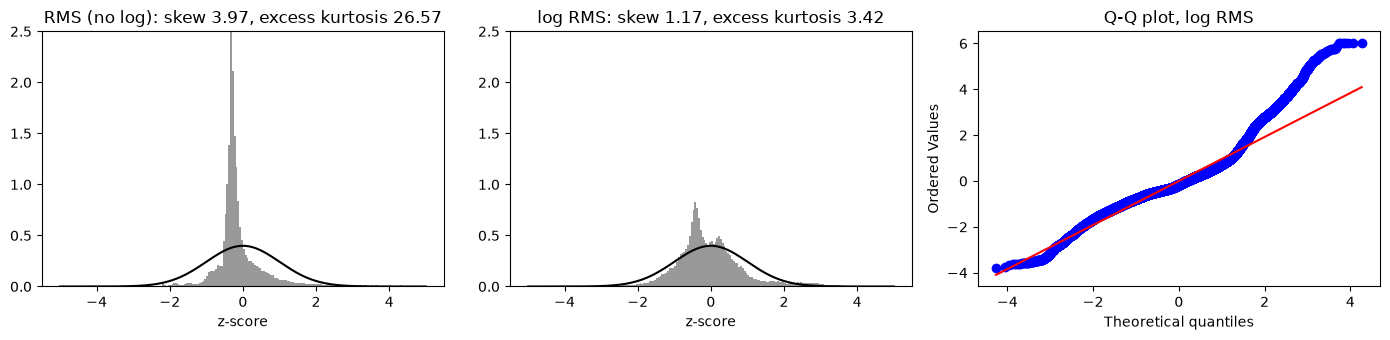

Mean z-scored EMG per subject and sleep stage:
stage       1     2     W
subject                  
TT004   -0.24 -0.22  0.19
TT005   -0.44 -0.67  0.10
TT006   -0.19   NaN  0.01
TT007   -1.70 -2.06  0.29
TT008   -1.20   NaN  0.04
TT009     NaN   NaN  0.00
TT011     NaN   NaN  0.00
TT012     NaN -1.65  0.32
TT013   -0.23 -0.74  0.07
TT014     NaN  0.14 -0.07
TT015     NaN   NaN  0.00
TT017   -0.52 -0.58  0.33
TT018     NaN   NaN  0.00


In [28]:
from scipy import stats

# Standardised within each session, as it will be in Y_prep. The HMM only needs the EMG to be Gaussian *within* a state:
# pooled over states the histogram may be skewed or bimodal (e.g. wake vs sleep tone), which is fine
z = np.concatenate([(e - e.mean()) / e.std() for e in emg_feat.values()])
z_lin = np.concatenate([(np.exp(e) - np.exp(e).mean()) / np.exp(e).std() for e in emg_feat.values()])  # without the log

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
xx = np.linspace(-5, 5, 200)
for ax, v, title in [(axes[0], z_lin, 'RMS (no log)'), (axes[1], z, 'log RMS')]:
    ax.hist(v, bins=200, range=(-5, 5), density=True, color='0.6')
    ax.plot(xx, stats.norm.pdf(xx), 'k')
    ax.set_title(f'{title}: skew {stats.skew(v):.2f}, excess kurtosis {stats.kurtosis(v):.2f}')
    ax.set_xlabel('z-score')
    ax.set_ylim(0, 2.5)
stats.probplot(z, dist='norm', plot=axes[2])
axes[2].set_title('Q-Q plot, log RMS')
plt.tight_layout()
plt.show()

# Per sleep stage: the EMG should drop from W to N1/N2 (muscle tone)
by_stage = []
for s, e in emg_feat.items():
    row = sessions_meta.loc[s]
    t_abs = row.crop_start_s + (np.arange(len(e)) + 0.5) / FS_ENV  # s from recording start of each envelope sample
    stg = [sleep_stages.get(row.subject, {}).get(int(t // EPOCH_S)) for t in t_abs]
    by_stage.append(pd.DataFrame({'subject': row.subject, 'stage': stg, 'z': (e - e.mean()) / e.std()}))
by_stage = pd.concat(by_stage).dropna()
print('Mean z-scored EMG per subject and sleep stage:')
print(by_stage.pivot_table(index='subject', columns='stage', values='z').round(2))

The data distribution seems sufficiently Gaussian, the log brings the EMG from strongly non-Gaussian into the same range as the EEG features.

Q-Q plot: the data stays close to the red line between -3 and ~2, then the points bend upward --> heavy right tail, where points have much higher EMG tnan a Gaussian would predict. These might be muscle bursts from movements, swallowing and maybe the presses.

Add the EMG feature to the Y matrix:


In [29]:
assert 'EMG' not in feature_names, 'EMG already added: re-run the data preparation cells first'

# Every session must have the same features, so the sessions without EMG are dropped
keep = sessions_meta.index.isin(list(emg_feat))
if not keep.all():
    print(f'dropping {sessions_meta.subject[~keep].tolist()} (no EMG channel)')
Y_prep = np.vstack([np.column_stack([Y_prep[a:b], emg_feat[s]])
                    for s, (a, b) in zip(sessions_meta.index[keep], indices_prep[keep])])
lengths = np.diff(indices_prep[keep], axis=1)[:, 0]
ends_prep = np.cumsum(lengths)
indices_prep = np.column_stack([ends_prep - lengths, ends_prep])
indices = indices[keep]  # still points into the raw EEG Y, which is left untouched
sessions_meta = sessions_meta[keep].reset_index(drop=True)

# Standardise the EMG within each subject, like the EEG features
for sub in sessions_meta.subject.unique():
    rows = np.concatenate([np.arange(a, b) for a, b in indices_prep[(sessions_meta.subject == sub).values]])
    Y_prep[rows, -1] = (Y_prep[rows, -1] - Y_prep[rows, -1].mean()) / Y_prep[rows, -1].std()

feature_names = feature_names + ['EMG']
MODEL_TAG += '_emg'
assert np.isfinite(Y_prep).all(), 'NaN/inf in Y_prep'
print(f'Y_prep shape: {Y_prep.shape}  ({fs_prep} Hz, {len(feature_names)} features)')
print(f'indices_prep shape: {indices_prep.shape}')

dropping ['TT001', 'TT002'] (no EMG channel)
Y_prep shape: (69500, 26)  (4 Hz, 26 features)
indices_prep shape: (13, 2)


### EOG signal

In [33]:
# raw.pick('eeg') dropped the EOG (IO) above, so re-open each session's file and crop exactly the same window as its EEG
eog_raw = {}  # session index (row of sessions_meta) -> (n_times,) EOG in microvolts, only for the sessions that have one
for s, row in sessions_meta.iterrows():
    raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
    if 'IO' not in raw.ch_names:
        print(f"  no EOG channel for {row.subject}")
        continue
    n = row.end - row.start  # number of EEG samples of this session
    raw.crop(tmin=row.crop_start_s, tmax=row.crop_start_s + n / fs, include_tmax=False)
    eog_raw[s] = raw.get_data(picks=['IO'], reject_by_annotation=None, verbose=0)[0] * 1e6
    del raw
    assert len(eog_raw[s]) == n, f'{row.subject}: {len(eog_raw[s])} EOG samples for {n} EEG samples'

print(f'EOG found for {len(eog_raw)} / {len(sessions_meta)} sessions')

C:\Users\eva\AppData\Local\Temp\ipykernel_16616\4094926285.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT004_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\4094926285.py:4: RuntimeWarning: This filename (C:\Users\eva\Documents\Master\ICM\Ilo\EEG\TT005_preprocessed.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(row.file, preload=False, verbose=0)
C:\Users\eva\AppData\Local\Temp\ipykernel_16616\4094926285.py:4: RuntimeWarning: This filename

EOG found for 13 / 13 sessions


Create an EOG-derived feature:


In [ ]:
def eog_envelope(x, fs, band, smooth_s):
    """(n_times,) EOG -> (n_times_env,) log amplitude envelope in band, on the same grid as band_power_envelopes."""
    sos = signal.butter(2, band, 'bandpass', output='sos', fs=fs)
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, x)))
    step = int(fs / FS_ENV)
    return np.log(uniform_filter1d(env, int(smooth_s * fs), mode='nearest')[step // 2::step])


# session index -> (n_times_env, n_eog_features), one column per entry of EOG_FEATURES
eog_feat = {s: np.column_stack([eog_envelope(x, fs, band, smooth_s) for band, smooth_s in EOG_FEATURES.values()])
            for s, x in eog_raw.items()}
for s, e in eog_feat.items():
    assert len(e) == indices_prep[s, 1] - indices_prep[s, 0], f'{sessions_meta.subject[s]}: EOG and EEG features have different lengths'

Verify Gaussianity:


In [ ]:
from scipy import stats

# Standardised within each session, as it will be in Y_prep. The HMM only needs the EOG to be Gaussian *within* a state:
# pooled over states the histogram may be skewed or bimodal (e.g. wake vs sleep eye movements), which is fine
z = np.vstack([(e - e.mean(axis=0)) / e.std(axis=0) for e in eog_feat.values()])
print(f'correlation between the EOG features:\n{pd.DataFrame(np.corrcoef(z.T), index=list(EOG_FEATURES), columns=list(EOG_FEATURES)).round(2)}')

fig, axes = plt.subplots(len(EOG_FEATURES), 2, figsize=(10, 3.5 * len(EOG_FEATURES)), squeeze=False)
xx = np.linspace(-5, 5, 200)
for i, name in enumerate(EOG_FEATURES):
    v = z[:, i]
    axes[i, 0].hist(v, bins=200, range=(-5, 5), density=True, color='0.6')
    axes[i, 0].plot(xx, stats.norm.pdf(xx), 'k')
    axes[i, 0].set_title(f'{name} (log envelope): skew {stats.skew(v):.2f}, excess kurtosis {stats.kurtosis(v):.2f}')
    axes[i, 0].set_xlabel('z-score')
    stats.probplot(v, dist='norm', plot=axes[i, 1])
    axes[i, 1].set_title(f'Q-Q plot, {name}')
plt.tight_layout()
plt.show()

# Per sleep stage: eye movements should become rarer from W to N2
by_stage = []
for s, e in eog_feat.items():
    row = sessions_meta.loc[s]
    t_abs = row.crop_start_s + (np.arange(len(e)) + 0.5) / FS_ENV  # s from recording start of each envelope sample
    stg = [sleep_stages.get(row.subject, {}).get(int(t // EPOCH_S)) for t in t_abs]
    by_stage.append(pd.DataFrame({'subject': row.subject, 'stage': stg,
                                  **dict(zip(EOG_FEATURES, ((e - e.mean(axis=0)) / e.std(axis=0)).T))}))
by_stage = pd.concat(by_stage).dropna()
print('\nMean z-scored EOG per subject and sleep stage:')
print(by_stage.pivot_table(index='subject', columns='stage', values=list(EOG_FEATURES)).round(2))

The data distribution seems sufficiently Gaussian, the log brings the EMG from strongly non-Gaussian into the same range as the EEG features.

Q-Q plot: the data stays close to the red line between -3 and ~2, then the points bend upward --> heavy right tail, where points have much higher EMG tnan a Gaussian would predict. These might be muscle bursts from movements, swallowing and maybe the presses.

Add the EMG feature to the Y matrix:

In [ ]:
assert not set(EOG_FEATURES) & set(feature_names), 'EOG already added: re-run the data preparation cells first'

# Every session must have the same features, so the sessions without EOG are dropped
keep = sessions_meta.index.isin(list(eog_feat))
if not keep.all():
    print(f'dropping {sessions_meta.subject[~keep].tolist()} (no EOG channel)')
Y_prep = np.vstack([np.column_stack([Y_prep[a:b], eog_feat[s]])
                    for s, (a, b) in zip(sessions_meta.index[keep], indices_prep[keep])])
lengths = np.diff(indices_prep[keep], axis=1)[:, 0]
ends_prep = np.cumsum(lengths)
indices_prep = np.column_stack([ends_prep - lengths, ends_prep])
indices = indices[keep]  # still points into the raw EEG Y, which is left untouched
sessions_meta = sessions_meta[keep].reset_index(drop=True)

# Standardise the EOG columns within each subject, like the EEG features
n_eog = len(EOG_FEATURES)
for sub in sessions_meta.subject.unique():
    rows = np.concatenate([np.arange(a, b) for a, b in indices_prep[(sessions_meta.subject == sub).values]])
    Y_prep[rows, -n_eog:] = (Y_prep[rows, -n_eog:] - Y_prep[rows, -n_eog:].mean(axis=0)) / Y_prep[rows, -n_eog:].std(axis=0)

feature_names = feature_names + list(EOG_FEATURES)
MODEL_TAG += '_eog'
assert np.isfinite(Y_prep).all(), 'NaN/inf in Y_prep'
print(f'Y_prep shape: {Y_prep.shape}  ({fs_prep} Hz, {len(feature_names)} features)')
print(f'indices_prep shape: {indices_prep.shape}')

### ECG signal

## Include behavioral data
### IRT